# Détection de fraude à la carte bancaire

Dans ce projet, je compare plusieurs modèles de machine learning pour détecter les fraudes à la carte bancaire :
- la régression logistique (le modèle classique, utilisé comme référence)
- le Random Forest
- XGBoost
- un réseau de neurones (MLP)

Je veux répondre à trois questions :
1. Est-ce que les modèles plus complexes détectent mieux la fraude que la régression logistique ?
2. Est-ce qu'on peut expliquer leurs décisions ? (avec SHAP)
3. Combien ça représente en euros ?

Données : [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (Kaggle). Il y a 284 807 transactions. Les variables V1 à V28 sont anonymisées, seules `Time` et `Amount` sont en clair. La colonne `Class` vaut 1 pour une fraude et 0 sinon.

## 1. Chargement et exploration des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve, confusion_matrix
from xgboost import XGBClassifier
import shap

SEED = 42  # pour avoir les mêmes résultats à chaque exécution

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("creditcard.csv")
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# valeurs manquantes et doublons
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())

# nombre de fraudes
print(df["Class"].value_counts())

taux_fraude = df["Class"].mean() * 100
print("Taux de fraude :", round(taux_fraude, 3), "%")

Valeurs manquantes : 0


Doublons : 1081
Class
0    284315
1       492
Name: count, dtype: int64
Taux de fraude : 0.173 %


Il n'y a pas de valeurs manquantes. Il y a 1 081 doublons, mais je les garde car deux transactions identiques peuvent exister en vrai.

Le plus important : il y a seulement **0,17 % de fraudes**. Si un modèle disait toujours "pas de fraude", il aurait 99,83 % de bonnes réponses, sans détecter aucune fraude. Donc je n'utilise pas l'accuracy. J'utilise plutôt la précision, le rappel, le F1 et la PR-AUC.

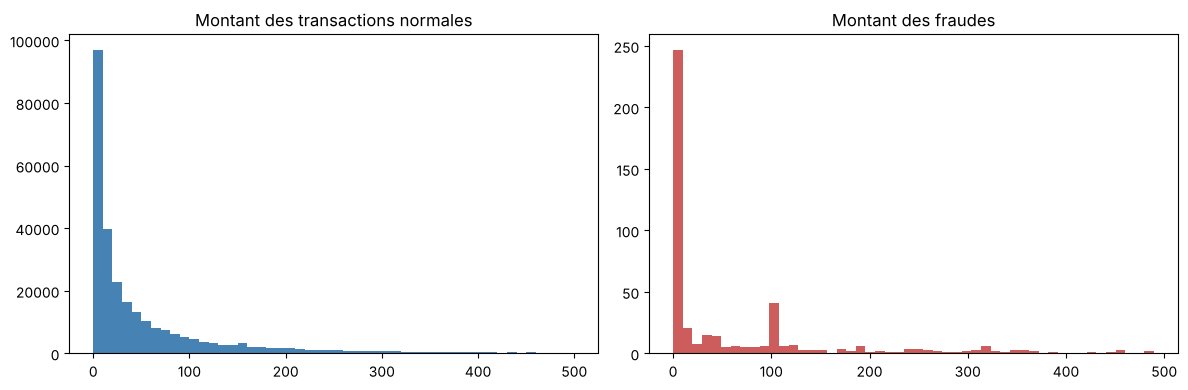

Montant médian des transactions normales : 22.0
Montant médian des fraudes : 9.25


In [4]:
normales = df[df["Class"] == 0]
fraudes = df[df["Class"] == 1]

# je garde seulement les montants < 500 € pour que le graphique soit lisible
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(normales[normales["Amount"] < 500]["Amount"], bins=50, color="steelblue")
plt.title("Montant des transactions normales")

plt.subplot(1, 2, 2)
plt.hist(fraudes[fraudes["Amount"] < 500]["Amount"], bins=50, color="indianred")
plt.title("Montant des fraudes")

plt.tight_layout()
plt.savefig("figures/montants.png", dpi=120)
plt.show()

print("Montant médian des transactions normales :", normales["Amount"].median())
print("Montant médian des fraudes :", fraudes["Amount"].median())

Les fraudes ont souvent de petits montants (médiane autour de 9 € contre 22 € pour les transactions normales). Les fraudeurs testent souvent la carte avec un petit achat.

## 2. Séparation des données

Je sépare les données en 3 parties :
- **train (60 %)** : pour entraîner les modèles
- **validation (20 %)** : pour choisir le seuil de décision
- **test (20 %)** : pour évaluer les modèles à la fin

`stratify` permet de garder le même pourcentage de fraudes dans les 3 parties.

In [5]:
X = df.drop(columns="Class")   # les variables
y = df["Class"]                # la cible : 1 = fraude, 0 = normale

# d'abord 60 % train et 40 % reste
X_train, X_reste, y_train, y_reste = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)

# ensuite le reste est coupé en deux : 20 % validation et 20 % test
X_val, X_test, y_val, y_test = train_test_split(
    X_reste, y_reste, test_size=0.5, stratify=y_reste, random_state=SEED)

print("Train :", len(y_train), "lignes,", y_train.sum(), "fraudes")
print("Validation :", len(y_val), "lignes,", y_val.sum(), "fraudes")
print("Test :", len(y_test), "lignes,", y_test.sum(), "fraudes")

Train : 170884 lignes, 295 fraudes
Validation : 56961 lignes, 98 fraudes
Test : 56962 lignes, 99 fraudes


## 3. Entraînement des modèles

La régression logistique et le réseau de neurones ont besoin que les variables soient à la même échelle. Je les normalise avec `StandardScaler`. Les modèles à base d'arbres (Random Forest, XGBoost) n'en ont pas besoin.

Pour gérer le déséquilibre, je donne plus de poids aux fraudes pendant l'entraînement (`class_weight` ou `scale_pos_weight`).

In [6]:
# normalisation (on apprend la moyenne et l'écart-type seulement sur le train)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

# ici je vais garder les probabilités de fraude de chaque modèle
proba_val = {}
proba_test = {}

In [7]:
# Modèle 1 : régression logistique
logit = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
logit.fit(X_train_sc, y_train)

proba_val["Régression logistique"] = logit.predict_proba(X_val_sc)[:, 1]
proba_test["Régression logistique"] = logit.predict_proba(X_test_sc)[:, 1]

In [8]:
# Modèle 2 : Random Forest (200 arbres)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                            class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)

proba_val["Random Forest"] = rf.predict_proba(X_val)[:, 1]
proba_test["Random Forest"] = rf.predict_proba(X_test)[:, 1]

In [9]:
# Modèle 3 : XGBoost
# scale_pos_weight = nombre de transactions normales / nombre de fraudes
poids = (y_train == 0).sum() / (y_train == 1).sum()
print("Poids des fraudes :", round(poids))

xgb = XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=poids, eval_metric="aucpr",
                    n_jobs=-1, random_state=SEED)
xgb.fit(X_train, y_train)

proba_val["XGBoost"] = xgb.predict_proba(X_val)[:, 1]
proba_test["XGBoost"] = xgb.predict_proba(X_test)[:, 1]

Poids des fraudes : 578


In [10]:
# Modèle 4 : réseau de neurones (2 couches de 64 et 32 neurones)
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                    max_iter=200, random_state=SEED)
mlp.fit(X_train_sc, y_train)

proba_val["Réseau de neurones"] = mlp.predict_proba(X_val_sc)[:, 1]
proba_test["Réseau de neurones"] = mlp.predict_proba(X_test_sc)[:, 1]

## 4. Choix du seuil

Chaque modèle donne une probabilité de fraude entre 0 et 1. Il faut choisir un **seuil** : au-dessus du seuil, on déclenche une alerte.

Par défaut le seuil est 0,5, mais ce n'est pas forcément le meilleur ici. Pour chaque modèle, je teste plusieurs seuils sur la **validation** et je garde celui qui donne le meilleur F1.

In [11]:
def meilleur_seuil(y_vrai, proba):
    precision, rappel, seuils_possibles = precision_recall_curve(y_vrai, proba)
    f1 = 2 * precision * rappel / (precision + rappel + 1e-12)
    meilleur = np.argmax(f1[:-1])   # la position du meilleur F1
    return seuils_possibles[meilleur]

seuils = {}
for nom in proba_val:
    seuils[nom] = meilleur_seuil(y_val, proba_val[nom])
    print(nom, ": seuil =", round(seuils[nom], 3))

Régression logistique : seuil = 1.0
Random Forest : seuil = 0.41
XGBoost : seuil = 0.792
Réseau de neurones : seuil = 0.31


## 5. Résultats sur le test

- **AUC-ROC** et **PR-AUC** : qualité générale du modèle, sur tous les seuils (1 = parfait)
- **Précision** : parmi les alertes, combien sont de vraies fraudes
- **Rappel** : parmi les vraies fraudes, combien on en détecte
- **F1** : un mélange de la précision et du rappel

In [12]:
resultats = []

for nom in proba_test:
    proba = proba_test[nom]
    alerte = (proba >= seuils[nom]).astype(int)   # 1 = alerte, 0 = pas d'alerte

    resultats.append({
        "Modèle": nom,
        "AUC-ROC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
        "Précision": precision_score(y_test, alerte),
        "Rappel": recall_score(y_test, alerte),
        "F1": f1_score(y_test, alerte),
    })

resultats = pd.DataFrame(resultats).set_index("Modèle").round(3)
resultats.to_csv("figures/resultats.csv")
resultats

,AUC-ROC,PR-AUC,Précision,Rappel,F1
Modèle,,,,,
Régression logistique,0.966,0.758,0.886,0.788,0.834
Random Forest,0.977,0.875,0.931,0.818,0.871
XGBoost,0.977,0.872,0.931,0.818,0.871
Réseau de neurones,0.958,0.854,0.844,0.818,0.831


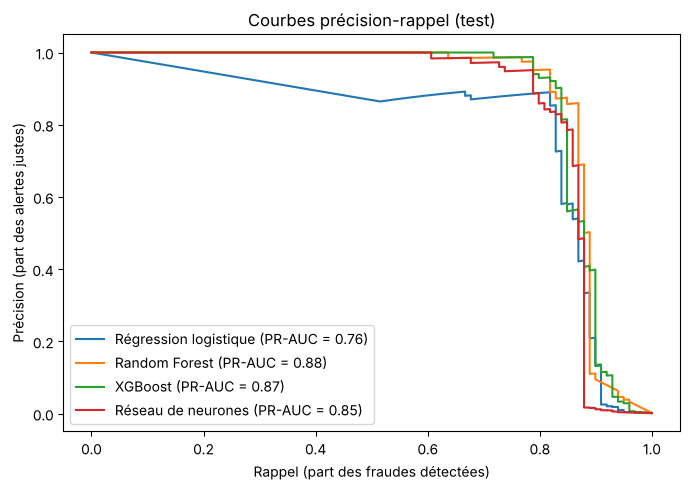

In [13]:
plt.figure(figsize=(7, 5))

for nom in proba_test:
    precision, rappel, _ = precision_recall_curve(y_test, proba_test[nom])
    pr_auc = average_precision_score(y_test, proba_test[nom])
    plt.plot(rappel, precision, label=nom + " (PR-AUC = " + str(round(pr_auc, 2)) + ")")

plt.xlabel("Rappel (part des fraudes détectées)")
plt.ylabel("Précision (part des alertes justes)")
plt.title("Courbes précision-rappel (test)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/courbes_pr.png", dpi=120)
plt.show()

In [14]:
# combien de fraudes détectées, manquées, et de fausses alertes ?
for nom in ["Régression logistique", "XGBoost"]:
    alerte = (proba_test[nom] >= seuils[nom]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, alerte).ravel()
    print(nom)
    print("  fraudes détectées :", tp)
    print("  fraudes manquées :", fn)
    print("  fausses alertes :", fp)

Régression logistique
  fraudes détectées : 78
  fraudes manquées : 21
  fausses alertes : 10
XGBoost
  fraudes détectées : 81
  fraudes manquées : 18
  fausses alertes : 6


**Ce que je remarque :**
- L'AUC-ROC est très proche pour tous les modèles (entre 0,96 et 0,98), donc elle ne permet pas vraiment de les comparer.
- La PR-AUC montre une vraie différence : environ 0,88 pour XGBoost et Random Forest, contre 0,76 pour la régression logistique.
- XGBoost détecte plus de fraudes que la régression logistique, avec moins de fausses alertes.
- Attention : il n'y a que 99 fraudes dans le test, donc une différence de 2 ou 3 fraudes reste petite.

## 6. Expliquer les décisions avec SHAP

XGBoost est plus performant, mais c'est un modèle difficile à lire. SHAP montre la contribution de chaque variable à la décision :
- pour toutes les transactions (quelles variables sont les plus importantes)
- pour une seule transaction (pourquoi elle a été détectée comme fraude)

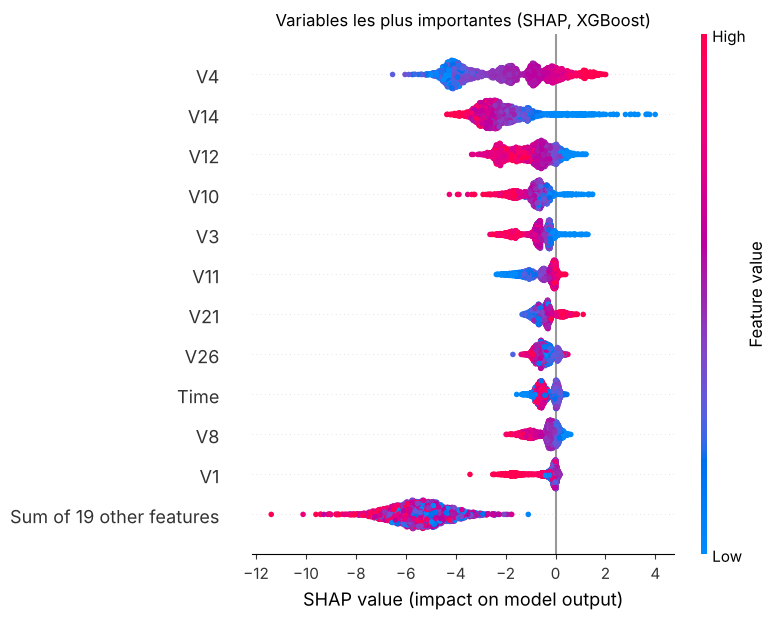

In [15]:
# je prends 3000 transactions du test pour aller plus vite
echantillon = X_test.sample(3000, random_state=SEED)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer(echantillon)

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("Variables les plus importantes (SHAP, XGBoost)")
plt.tight_layout()
plt.savefig("figures/shap_global.png", dpi=120, bbox_inches="tight")
plt.show()

Probabilité de fraude : 1.0


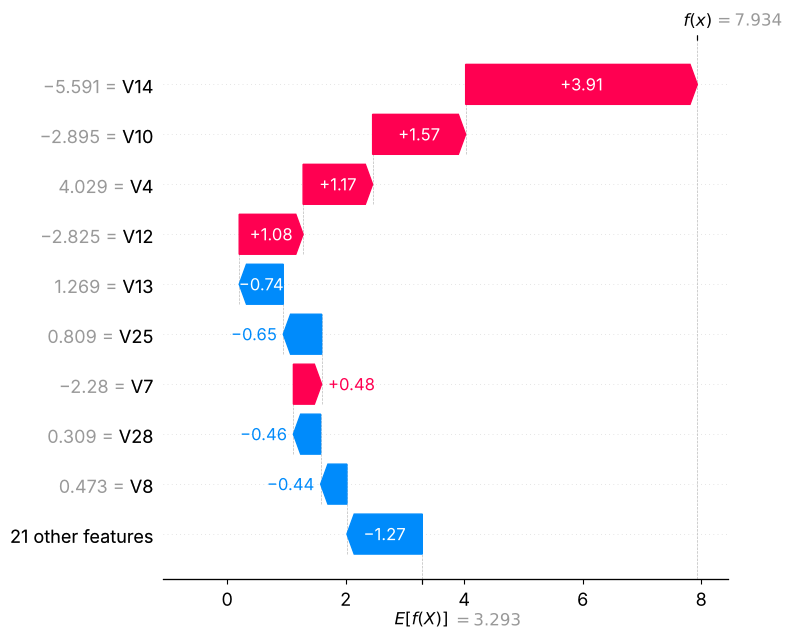

In [16]:
# explication d'une fraude que XGBoost a bien détectée
detectees = (y_test == 1) & (proba_test["XGBoost"] >= seuils["XGBoost"])
une_fraude = X_test[detectees].iloc[[0]]

print("Probabilité de fraude :", round(xgb.predict_proba(une_fraude)[0, 1], 3))

shap.plots.waterfall(explainer(une_fraude)[0], max_display=10, show=False)
plt.tight_layout()
plt.savefig("figures/shap_exemple.png", dpi=120, bbox_inches="tight")
plt.show()

Quelques variables comptent beaucoup plus que les autres, surtout V14, V4, V12 et V10. Le deuxième graphique montre, pour une transaction, quelles variables ont fait monter ou baisser le risque.

Limite : les variables sont anonymisées, donc on ne sait pas ce qu'elles représentent. Avec de vraies données de banque (pays, type de commerçant, heure…), les explications seraient plus faciles à comprendre pour les équipes métier.

## 7. Le résultat en euros

Hypothèses simples (à valider avec le métier) :
- une fraude détectée est bloquée : on évite de perdre son montant
- chaque alerte (vraie ou fausse) coûte 5 € à traiter (vérification, appel au client)

Gain net = argent des fraudes évitées − coût des alertes

In [17]:
COUT_ALERTE = 5
montants = X_test["Amount"].values
y_vrai = y_test.values

gains = []
for nom in proba_test:
    alerte = proba_test[nom] >= seuils[nom]

    fraudes_evitees = montants[alerte & (y_vrai == 1)].sum()
    cout_alertes = alerte.sum() * COUT_ALERTE

    gains.append({
        "Modèle": nom,
        "Alertes": alerte.sum(),
        "Fraudes évitées (€)": round(fraudes_evitees),
        "Coût des alertes (€)": cout_alertes,
        "Gain net (€)": round(fraudes_evitees - cout_alertes),
    })

gains = pd.DataFrame(gains).set_index("Modèle")
gains.to_csv("figures/roi.csv")
gains

,Alertes,Fraudes évitées (€),Coût des alertes (€),Gain net (€)
Modèle,,,,
Régression logistique,88,7239,440,6799
Random Forest,87,7156,435,6721
XGBoost,87,7156,435,6721
Réseau de neurones,96,7150,480,6670


Surprise : même si XGBoost a une meilleure PR-AUC, en euros la différence avec la régression logistique est très petite. La régression logistique a détecté quelques fraudes avec de gros montants. Le F1 compte toutes les fraudes de la même façon, alors qu'en euros une fraude de 1 000 € compte plus qu'une fraude de 5 €.

Donc j'essaie un autre seuil : celui qui donne le **meilleur gain en euros** sur la validation.

In [18]:
def gain_net(y_vrai, proba, montants, seuil):
    alerte = proba >= seuil
    fraudes_evitees = montants[alerte & (y_vrai == 1)].sum()
    return fraudes_evitees - alerte.sum() * COUT_ALERTE

montants_val = X_val["Amount"].values

gains_cout = []
for nom in proba_val:
    # seuils à tester : les 500 probabilités les plus élevées de la validation
    # (les fraudes ont des probabilités proches de 1, donc on cherche dans cette zone)
    seuils_a_tester = np.sort(proba_val[nom])[-500:]

    # on cherche le meilleur seuil sur la validation
    gains_val = [gain_net(y_val.values, proba_val[nom], montants_val, s) for s in seuils_a_tester]
    seuil_cout = seuils_a_tester[np.argmax(gains_val)]

    # on l'applique au test
    gains_cout.append({
        "Modèle": nom,
        "Seuil": round(seuil_cout, 4),
        "Gain net test (€)": round(gain_net(y_vrai, proba_test[nom], montants, seuil_cout)),
    })

gains_cout = pd.DataFrame(gains_cout).set_index("Modèle")
gains_cout.to_csv("figures/roi_seuil_cout.csv")
gains_cout

,Seuil,Gain net test (€)
Modèle,,
Régression logistique,1.0000,6888
Random Forest,0.2496,6697
XGBoost,0.5215,6730
Réseau de neurones,0.3098,6670


Les différences entre les modèles se comptent en quelques centaines d'euros sur environ 57 000 transactions. Le choix du modèle et du seuil dépend donc beaucoup du coût réel d'une alerte. Il faudrait fixer ces coûts avec les équipes métier avant de choisir.

## 8. Conclusion

- XGBoost et Random Forest détectent mieux les fraudes que la régression logistique (PR-AUC d'environ 0,88 contre 0,76), avec moins de fausses alertes.
- Mais en euros, la différence est très petite. Un meilleur score ne veut pas toujours dire un meilleur gain.
- SHAP permet d'expliquer les décisions d'un modèle complexe, ce qui est important en banque.

**Limites :**
- Le découpage est aléatoire. Avec de vraies données, il faudrait plutôt entraîner sur le passé et tester sur le futur.
- Les variables sont anonymisées.
- Il y a seulement 99 fraudes dans le test.